# Cidade Limpa — Classificador REGULAR × IRREGULAR (MobileNetV2)

Este notebook treina o modelo de visão computacional do projeto **Cidade Limpa**
(FIAP Global Solution 2026.2). Ele é **autocontido**: replica o pipeline de
`ml/src/` para rodar aqui no Colab, sem depender do repositório privado.

## O que ele faz

1. Prepara um dataset de imagens em duas classes;
2. Divide em treino / validação / teste (reprodutível);
3. Treina a cabeça de um **MobileNetV2** (transfer learning, ImageNet);
4. Faz o **ajuste fino** das últimas camadas;
5. Avalia no teste e calcula **accuracy, precision, recall, F1 e matriz de confusão**;
6. Salva os pesos (`.keras`) e os metadados (JSON) com as métricas **reais**.

## Antes de começar

- Ative o ambiente com **GPU** (Ambiente de execução → Alterar tipo de ambiente).
- Tenha as imagens nas pastas `REGULAR/` e `IRREGULAR/` (seção 1).
- **Nenhum resultado é inventado:** tudo exibido vem da execução real.

## Ao final

Baixe `cidade_limpa_mobilenetv2.keras` e `cidade_limpa_mobilenetv2.metadata.json`
e coloque ambos em `ml/models/` no repositório local (seção 7).


In [1]:
import shutil
import zipfile
from pathlib import Path

import numpy as np
import tensorflow as tf
import keras

print("TensorFlow", tf.__version__)
print("Keras", keras.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU disponível:", gpus if gpus else "NÃO — ative em Ambiente de execução → tipo de ambiente")

TensorFlow 2.21.0
Keras 3.13.2
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Prepare o dataset (duas classes)

```
/content/ml/data/raw/
├── REGULAR/       # descarte regular (lixo acondicionado, lixeiras organizadas, reciclagem)
└── IRREGULAR/     # descarte irregular (entulho, transbordamento, lixo em via pública)
```

Escolha **uma** das opções (A, B ou C). Recomendado: **100+ imagens por classe**
(mínimo para rodar: 10 por classe).

In [9]:
RAW = Path("/content/ml/data/raw")
REGULAR = RAW / "REGULAR"
IRREGULAR = RAW / "IRREGULAR"
PROCESSED = Path("/content/ml/data/processed")
MODELOS = Path("/content/ml/models")
RELATORIOS = Path("/content/ml/reports")

for d in (REGULAR, IRREGULAR, PROCESSED, MODELOS, RELATORIOS):
    d.mkdir(parents=True, exist_ok=True)

EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def contar(pasta):
    if not pasta.is_dir():
        return 0
    return sum(1 for f in pasta.iterdir() if f.is_file() and f.suffix.lower() in EXT)

print({c: contar(RAW / c) for c in ("REGULAR", "IRREGULAR")})

{'REGULAR': 0, 'IRREGULAR': 0}


### Opção A — Subir um ZIP (duas pastas REGULAR/ e IRREGULAR/)

In [10]:
from google.colab import files

def upload_zip():
    enviados = files.upload()
    for nome, dados in enviados.items():
        if nome.endswith(".zip"):
            caminho = Path(nome)
            caminho.write_bytes(dados)
            with zipfile.ZipFile(caminho) as pacote:
                pacote.extractall(RAW)
            print("Extraído em", RAW)
            caminho.unlink()

upload_zip()  # descomente para enviar
print({c: contar(RAW / c) for c in ("REGULAR", "IRREGULAR")})

KeyboardInterrupt: 

### Opção B — Google Drive

In [11]:
from google.colab import drive
drive.mount("/content/drive")

# AJUSTE: pasta no Drive com REGULAR/ e IRREGULAR/ dentro
DRIVE_DATASET = Path("/content/drive/MyDrive/Global_Solution_Dataset")
print("Drive montado; dataset em", DRIVE_DATASET)

Mounted at /content/drive
Drive montado; dataset em /content/drive/MyDrive/Global_Solution_Dataset


### Opção C — Importar de uma pasta arbitrária (Drive ou Kaggle)

Indique no `MAPPING` quais subpastas da fonte correspondem a cada classe e rode.
Fontes públicas úteis: Kaggle **"Garbage Classification"** (12 classes) ou
**"Waste Segregation Image Dataset"** (lixo e reciclagem).

In [ ]:
FONTE = globals().get("DRIVE_DATASET")

def importar_mapeado(fonte, mapeamento):
    assert fonte and fonte.is_dir(), "Defina FONTE apontando para a pasta com as imagens."
    total = 0
    for origem, destino in mapeamento.items():
        pasta_origem = fonte / origem
        pasta_destino = RAW / destino
        if pasta_origem.is_dir():
            for arquivo in pasta_origem.iterdir():
                if arquivo.is_file() and arquivo.suffix.lower() in EXT:
                    shutil.copy(arquivo, pasta_destino / arquivo.name)
                    total += 1
            print(f"{origem} -> {destino}")
    print("Copiadas:", total, "imagens")

# importar_mapeado(FONTE, {"carton": "REGULAR", "plastic": "REGULAR", "trash": "IRREGULAR"})
print({c: contar(RAW / c) for c in ("REGULAR", "IRREGULAR")})

## 2. Divisão treino / validação / teste (reprodutível)

In [14]:
import random

SPLITS = {"train": 0.70, "val": 0.15, "test": 0.15}
SEED = 42
IMAGE_SIZE = 224
CLASSES = ("REGULAR", "IRREGULAR")
MODEL_VERSION = "mobilenetv2-v1"

def listar(pasta):
    return sorted(a for a in Path(pasta).iterdir() if a.is_file() and a.suffix.lower() in EXT)

def dividir(raw_dir, processed_dir, seed=SEED):
    if processed_dir.exists():
        shutil.rmtree(processed_dir)
    manifesto = {}
    for classe in CLASSES:
        imagens = listar(raw_dir / classe)
        random.Random(seed).shuffle(imagens)
        n = len(imagens)
        treino = int(n * SPLITS["train"])
        val = int(n * SPLITS["val"])
        limites = {"train": treino, "val": val, "test": n - treino - val}
        indice = 0
        for divisao, qtd in limites.items():
            destino = processed_dir / divisao / classe
            destino.mkdir(parents=True, exist_ok=True)
            for origem in imagens[indice : indice + qtd]:
                shutil.copy(origem, destino / origem.name)
            indice += qtd
            manifesto.setdefault(divisao, {})[classe] = qtd
    return manifesto

MANIFESTO = dividir(DRIVE_DATASET, PROCESSED)
print(MANIFESTO)

{'train': {'REGULAR': 72, 'IRREGULAR': 72}, 'val': {'REGULAR': 15, 'IRREGULAR': 15}, 'test': {'REGULAR': 16, 'IRREGULAR': 17}}


## 3. Modelo (MobileNetV2 + transfer learning)

A base vem do ImageNet; a normalização para [-1, 1] é uma camada interna do modelo,
então o backend pode enviar pixels crus em [0, 255] na inferência.

In [24]:
BATCH_SIZE = 5
DROPOUT = 0.3

def construir_modelo(image_size=IMAGE_SIZE, learning_rate=1e-3):
    base = keras.applications.MobileNetV2(
        input_shape=(image_size, image_size, 3), include_top=False, weights="imagenet",
    )
    base.trainable = False
    entradas = keras.Input(shape=(image_size, image_size, 3), name="imagem")
    x = keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="normalizacao")(entradas)
    x = base(x, training=False)
    x = keras.layers.GlobalAveragePooling2D(name="pooling_global")(x)
    x = keras.layers.Dropout(DROPOUT, name="dropout")(x)
    saidas = keras.layers.Dense(len(CLASSES), activation="softmax", name="classes")(x)
    modelo = keras.Model(inputs=entradas, outputs=saidas, name="cidade_limpa_mobilenetv2")
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return modelo

modelo = construir_modelo()
modelo.summary()

Model: "cidade_limpa_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_global                  │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4. Treino da cabeça (base congelada)

In [25]:
def carregar(divisao, shuffle):
    return keras.utils.image_dataset_from_directory(
        PROCESSED / divisao,
        labels="inferred",
        label_mode="categorical",
        class_names=list(CLASSES),
        image_size=(IMAGE_SIZE, IMAGE_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

treino = carregar("train", True)
validacao = carregar("val", False)

aumento = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.08),
    keras.layers.RandomZoom(0.12),
    keras.layers.RandomContrast(0.15),
    keras.layers.RandomBrightness(0.12),
], name="aumento_de_dados")

treino = treino.map(lambda x, y: (aumento(x, training=True), y)).prefetch(8)
validacao = validacao.prefetch(8)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", factor=0.5, patience=2, min_lr=1e-6),
]

historico_cabeca = modelo.fit(
    treino, validation_data=validacao, epochs=20, callbacks=callbacks, verbose=2,
).history
print("melhor val_accuracy (cabeça):", max(historico_cabeca["val_accuracy"]))

Found 144 files belonging to 2 classes.
Found 30 files belonging to 2 classes.
Epoch 1/20
29/29 - 28s - 969ms/step - accuracy: 0.5694 - loss: 0.8607 - val_accuracy: 0.5667 - val_loss: 0.7524 - learning_rate: 0.0010
Epoch 2/20
29/29 - 28s - 952ms/step - accuracy: 0.6458 - loss: 0.6789 - val_accuracy: 0.7333 - val_loss: 0.4933 - learning_rate: 0.0010
Epoch 3/20
29/29 - 8s - 289ms/step - accuracy: 0.6528 - loss: 0.6304 - val_accuracy: 0.7333 - val_loss: 0.4876 - learning_rate: 0.0010
Epoch 4/20
29/29 - 10s - 357ms/step - accuracy: 0.7153 - loss: 0.5936 - val_accuracy: 0.7333 - val_loss: 0.5251 - learning_rate: 0.0010
Epoch 5/20
29/29 - 10s - 354ms/step - accuracy: 0.7847 - loss: 0.4990 - val_accuracy: 0.8000 - val_loss: 0.4317 - learning_rate: 5.0000e-04
Epoch 6/20
29/29 - 9s - 299ms/step - accuracy: 0.7708 - loss: 0.4721 - val_accuracy: 0.7667 - val_loss: 0.4331 - learning_rate: 5.0000e-04
Epoch 7/20
29/29 - 10s - 336ms/step - accuracy: 0.8194 - loss: 0.3875 - val_accuracy: 0.7667 - val_

## 5. Ajuste fino das últimas camadas

In [32]:
base = modelo.get_layer("mobilenetv2_1.00_224")
base.trainable = True
for camada in base.layers[:-10]:
    camada.trainable = False
for camada in base.layers[-10:]:
    camada.trainable = not isinstance(camada, keras.layers.BatchNormalization)

modelo.compile(
    optimizer=keras.optimizers.Adam(1e-6),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

historico_ajuste = modelo.fit(
    treino, validation_data=validacao, epochs=11, callbacks=callbacks, verbose=2,
).history
print("melhor val_accuracy (ajuste fino):", max(historico_ajuste["val_accuracy"]))

Epoch 1/11
29/29 - 28s - 949ms/step - accuracy: 0.8125 - loss: 0.4310 - val_accuracy: 0.7667 - val_loss: 0.4422 - learning_rate: 1.0000e-06
Epoch 2/11
29/29 - 8s - 283ms/step - accuracy: 0.8125 - loss: 0.3661 - val_accuracy: 0.7667 - val_loss: 0.4468 - learning_rate: 1.0000e-06
Epoch 3/11
29/29 - 11s - 392ms/step - accuracy: 0.8125 - loss: 0.3356 - val_accuracy: 0.7667 - val_loss: 0.4505 - learning_rate: 1.0000e-06
Epoch 4/11
29/29 - 11s - 376ms/step - accuracy: 0.8542 - loss: 0.3674 - val_accuracy: 0.7667 - val_loss: 0.4458 - learning_rate: 1.0000e-06
melhor val_accuracy (ajuste fino): 0.7666666507720947


## 6. Avaliação no conjunto de teste (nunca visto no treino)

Found 33 files belonging to 2 classes.
MÉTRICAS REAIS (conjunto de teste)
  accuracy: 0.697
  precision_weighted: 0.6988
  recall_weighted: 0.697
  f1_weighted: 0.6953
  precision_macro: 0.6992
  recall_macro: 0.6949
  f1_macro: 0.6944
  classes: ['REGULAR', 'IRREGULAR']
  support_total: 33
              precision    recall  f1-score   support

     REGULAR       0.71      0.62      0.67        16
   IRREGULAR       0.68      0.76      0.72        17

    accuracy                           0.70        33
   macro avg       0.70      0.69      0.69        33
weighted avg       0.70      0.70      0.70        33



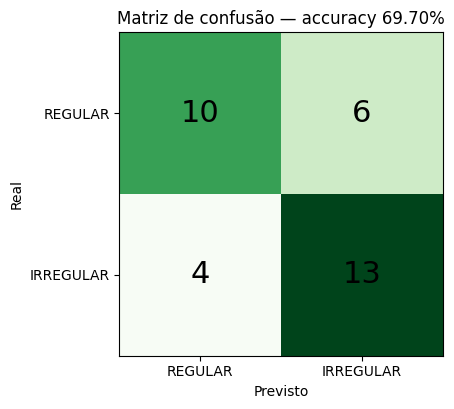

In [33]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)
import matplotlib.pyplot as plt

teste = carregar("test", False)

probabilidades = modelo.predict(teste, verbose=0)
y_real = np.concatenate([y.numpy() for _, y in teste], axis=0)
y_pred = np.argmax(probabilidades, axis=1)
y_true = np.argmax(y_real, axis=1)

metricas = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
    "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
    "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
    "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
    "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]).tolist(),
    "classes": list(CLASSES),
    "support_total": int(len(y_true)),
}

print("MÉTRICAS REAIS (conjunto de teste)")
for chave, valor in metricas.items():
    if chave != "confusion_matrix":
        print(f"  {chave}:", round(valor, 4) if isinstance(valor, float) else valor)
print(classification_report(y_true, y_pred, target_names=list(CLASSES), zero_division=0))

matriz = np.array(metricas["confusion_matrix"])
figura, eixo = plt.subplots(figsize=(5, 4.2))
eixo.imshow(matriz, cmap="Greens")
eixo.set_xticks([0, 1]); eixo.set_yticks([0, 1])
eixo.set_xticklabels(CLASSES); eixo.set_yticklabels(CLASSES)
eixo.set_xlabel("Previsto"); eixo.set_ylabel("Real")
for i in range(2):
    for j in range(2):
        eixo.text(j, i, str(matriz[i, j]), ha="center", va="center", fontsize=22)
eixo.set_title(f"Matriz de confusão — accuracy {metricas['accuracy']:.2%}")
plt.show()

## 7. Salvar pesos e metadados (e baixar)

In [31]:
import json
from datetime import datetime, timezone

modelo.save(MODELOS / "cidade_limpa_mobilenetv2.keras")

metadados = {
    "model_version": MODEL_VERSION,
    "created_at": datetime.now(timezone.utc).isoformat(),
    "architecture": "MobileNetV2 (ImageNet) + transfer learning",
    "classes": list(CLASSES),
    "image_size": IMAGE_SIZE,
    "input_range": "[0, 255] — normalização para [-1, 1] dentro do modelo",
    "metrics": metricas,
    "dataset": {"by_split": MANIFESTO, "source_counts": {c: contar(RAW / c) for c in CLASSES}},
    "training": {
        "epochs_head": 10, "epochs_finetune": 6, "batch_size": BATCH_SIZE, "seed": SEED,
        "tensorflow_version": tf.__version__, "keras_version": keras.__version__,
    },
    "warnings": [f"Classe {c} com menos de 100 imagens" for c in CLASSES if contar(RAW / c) < 100],
}

(RELATORIOS / "relatorio_treinamento.json").write_text(
    json.dumps(metadados, indent=2, ensure_ascii=False), encoding="utf-8"
)
(MODELOS / "cidade_limpa_mobilenetv2.metadata.json").write_text(
    json.dumps(metadados, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Artefatos salvos em", MODELOS)

from google.colab import files
files.download(str(MODELOS / "cidade_limpa_mobilenetv2.keras"))
files.download(str(MODELOS / "cidade_limpa_mobilenetv2.metadata.json"))
files.download(str(RELATORIOS / "relatorio_treinamento.json"))

Artefatos salvos em /content/ml/models


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7b. O que fazer localmente depois do treino

1. Coloque `cidade_limpa_mobilenetv2.keras` e
   `cidade_limpa_mobilenetv2.metadata.json` em **`ml/models/`** do repositório.
2. Opcional: coloque `relatorio_treinamento.json` e a matriz de confusão em **`ml/reports/`**.
3. Reinicie o backend:

   ```powershell
   cd backend
   python -m uvicorn app.main:app --reload --port 8000
   ```

4. Verifique:

   - `GET /health` → `"model_loaded": true`;
   - `GET /api/v1/classification/model-info` → métricas reais;
   - `POST /api/v1/classification/predict` com uma imagem → rótulo + confiança.

A partir daí, o registro de ocorrência passa a preencher `model_label`, `confidence`
e `model_version`, e o dashboard reflete a classificação da IA.